# 03 · Avaliações e clientes

A Olist cresce, e o crescimento vem do número de pedidos. Para esse crescimento se sustentar, o cliente precisa sair satisfeito e voltar. A pergunta que guia este notebook é

> **O atraso na entrega derruba a nota, e a nota baixa reduz a recompra?**

Duas tabelas respondem a ela: avaliações (`order_reviews`), com a nota de 1 a 5 que o cliente dá ao pedido, e clientes (customers), que permite reconhecer a mesma pessoa em pedidos diferentes.

## 4.1 Leitura das tabelas

Carrego pedidos, avaliações e clientes, e repito o estilo dos gráficos. Converto as datas que vou usar com pd.to_datetime().

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#a3a29d'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#a3a29d', 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
})

orders = pd.read_csv('../data/raw/olist_orders_dataset.csv')
for coluna in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    orders[coluna] = pd.to_datetime(orders[coluna])

reviews = pd.read_csv('../data/raw/olist_order_reviews_dataset.csv')
for coluna in ['review_creation_date', 'review_answer_timestamp']:
    reviews[coluna] = pd.to_datetime(reviews[coluna])

customers = pd.read_csv('../data/raw/olist_customers_dataset.csv')

print('Avaliações:', reviews.shape)
print('Clientes:', customers.shape)
reviews.head()

Avaliações: (99224, 7)
Clientes: (99441, 5)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


**99.224 avaliações** para 99.441 pedidos. Cada linha tem um `review_id`, o pedido, a nota, um título e um comentário opcionais, a data em que a pesquisa foi criada e a data da resposta.

**Hipótese:** cada pedido recebe no máximo uma avaliação, e alguns pedidos ficaram sem.

## 4.2 Granularidade das avaliações

Conto pedidos e avaliações distintos com nunique(). Se a hipótese estiver certa, os dois números devem ser iguais ao total de linhas.

In [2]:
print('Linhas:', len(reviews))
print('Pedidos distintos:', reviews['order_id'].nunique())
print('Avaliações distintas (review_id):', reviews['review_id'].nunique())
print()
print('Avaliações por pedido:')
print(reviews.groupby('order_id').size().value_counts())

Linhas: 99224
Pedidos distintos: 98673
Avaliações distintas (review_id): 98410

Avaliações por pedido:


1    98126
2      543
3        4
Name: count, dtype: int64


A hipótese não se sustenta nos dois sentidos:

- 547 pedidos têm 2 ou 3 avaliações.
- Há **98.410 review_id** para 99.224 linhas: a mesma avaliação aparece em mais de um pedido.

Começo pela avaliação repetida. **Hipótese:** é uma pesquisa só para uma compra que virou vários pedidos. Se for isso, os pedidos que dividem a avaliação são do mesmo cliente e foram feitos no mesmo momento. Para testar, junto a data de compra e o cliente (`customer_unique_id`, da tabela de clientes) a esses pedidos.

In [3]:
repete = reviews.groupby('review_id')['order_id'].transform('size') > 1
compartilhadas = (reviews[repete]
                  .merge(orders[['order_id', 'customer_id', 'order_purchase_timestamp']], on='order_id')
                  .merge(customers[['customer_id', 'customer_unique_id']], on='customer_id'))

por_avaliacao = compartilhadas.groupby('review_id').agg(
    clientes=('customer_unique_id', 'nunique'),
    primeira=('order_purchase_timestamp', 'min'),
    ultima=('order_purchase_timestamp', 'max'))
mesmo_minuto = (por_avaliacao['ultima'] - por_avaliacao['primeira']).dt.total_seconds() <= 60

print('Avaliações compartilhadas:', len(por_avaliacao))
print(f'Do mesmo cliente: {(por_avaliacao["clientes"] == 1).mean() * 100:.0f}%')
print(f'Pedidos feitos no mesmo minuto: {mesmo_minuto.mean() * 100:.0f}%')

Avaliações compartilhadas: 789
Do mesmo cliente: 100%
Pedidos feitos no mesmo minuto: 93%


As 789 avaliações compartilhadas são **100% do mesmo cliente**, e em 93% os pedidos foram feitos no mesmo minuto. Compatível com uma compra que virou vários pedidos e recebeu uma pesquisa só.

Uma compra pode virar vários pedidos, por exemplo, quando o carrinho tem produtos de vendedores diferentes e cada vendedor recebe o seu pedido. Para testar, vejo os vendedores desses pedidos (tabela de itens).

In [4]:
items = pd.read_csv('../data/raw/olist_order_items_dataset.csv')
vendedor = items.drop_duplicates(subset='order_id')[['order_id', 'seller_id']]
vendedores = compartilhadas.merge(vendedor, on='order_id').groupby('review_id')['seller_id'].nunique()
print(f'Avaliações compartilhadas com pedidos de vendedores diferentes: {(vendedores > 1).mean() * 100:.0f}%')

Avaliações compartilhadas com pedidos de vendedores diferentes: 63%


Em **63%** delas, os pedidos são de vendedores diferentes: compatível com o carrinho dividido em um pedido por vendedor. Nos outros 37%, o vendedor é o mesmo, e a base não mostra por que a compra foi separada.

**Decisão:** mantenho essas avaliações. A nota vale para cada pedido daquela compra.

Agora os pedidos com mais de uma avaliação. Vejo em quantos deles as notas são diferentes.

In [5]:
varias = reviews.groupby('order_id').filter(lambda pedido: len(pedido) > 1)
notas_diferentes = varias.groupby('order_id')['review_score'].nunique() > 1
print('Pedidos com mais de uma avaliação:', varias['order_id'].nunique())
print('Com notas diferentes entre si:', notas_diferentes.sum())

Pedidos com mais de uma avaliação: 547
Com notas diferentes entre si: 202


Em **202** dos 547 pedidos as notas divergem, então não dá para ignorar a repetição.

**Decisão:** fico com a última avaliação respondida de cada pedido (pela `review_answer_timestamp`), que é a opinião mais recente do cliente. Para isso ordeno pela data de resposta e uso drop_duplicates(keep='last').

In [6]:
nota_pedido = (reviews.sort_values('review_answer_timestamp')
                      .drop_duplicates(subset='order_id', keep='last'))
print('Uma avaliação por pedido:', len(nota_pedido), '| pedidos distintos:', nota_pedido['order_id'].nunique())

Uma avaliação por pedido: 98673 | pedidos distintos: 98673


## 4.3 Vazios e ligação com pedidos

In [7]:
print(reviews.isnull().sum())
print()
print('Avaliações sem pedido:', (~reviews['order_id'].isin(orders['order_id'])).sum())
print('Pedidos sem avaliação:', (~orders['order_id'].isin(reviews['order_id'])).sum())

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Avaliações sem pedido: 0


Pedidos sem avaliação: 768


- A nota e as datas não têm vazios. Os vazios estão no título (88%) e no **comentário** (59%): a avaliação existe mesmo sem comentário. A [descrição oficial da base no Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) confirma que o cliente dá a nota e *pode* escrever comentários, e que alguns clientes não escreveram.
- Nenhuma avaliação órfã; **768 pedidos** (0,8%) ficaram sem avaliação.

**Decisão:** as comparações usam a nota. Os pedidos sem avaliação ficam registrados como limitação.

## 4.4 Distribuição das notas

A nota é uma variável **ordinal** (1 a 5 estrelas): tem ordem, mas a distância entre 1 e 2 não é necessariamente a mesma que entre 4 e 5. Vejo a participação de cada nota com value_counts(normalize=True) e desenho em barras, que mostram cada opção de voto.

review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: proportion, dtype: float64


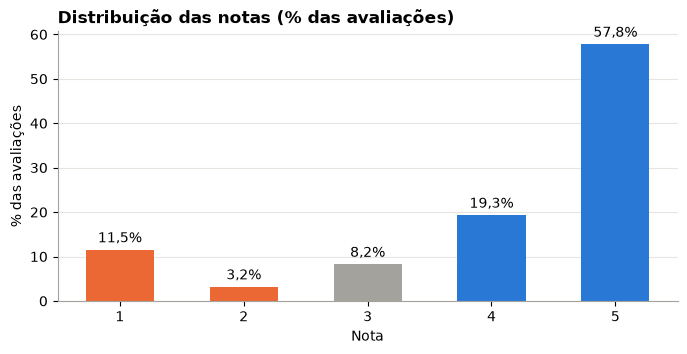

In [8]:
distribuicao = nota_pedido['review_score'].value_counts(normalize=True).sort_index() * 100
print(distribuicao.round(1))

plt.figure(figsize=(8, 3.5))
barras = plt.bar(distribuicao.index.astype(str), distribuicao.values, color=[LARANJA, LARANJA, CINZA, AZUL, AZUL], width=0.55)
plt.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in distribuicao.values], padding=3)
plt.title('Distribuição das notas (% das avaliações)')
plt.xlabel('Nota')
plt.ylabel('% das avaliações')
plt.show()

- 77% das notas são 4 ou 5, e a nota 5 sozinha tem 58%.
- A nota 1 tem 11,5%, mais que as notas 2 (3,2%) e 3 (8,2%) somadas.

As notas se concentram nas pontas: o cliente costuma estar satisfeito ou muito insatisfeito, raramente no meio. Com notas assim, a média resume mal: uma média 4 pode vir de muitos 5 e alguns 1, e esconde os 11% que deram a nota mínima.

**Decisão:** nas comparações, uso a **proporção de notas 1 e 2** (clientes insatisfeitos), e não a nota média.

## 4.5 Prazo de entrega e atraso

Para medir o atraso, aplico as decisões do notebook 01: só pedidos delivered com data de entrega, no recorte de jan/2017 a ago/2018, comparando o **dia** da entrega com o dia prometido. Uso .dt.normalize() para zerar a hora da entrega.

Calculo também o prazo de compra a entrega em dias (a diferença entre datas vem em segundos, por isso divido por 86.400).

In [9]:
entregues = orders[(orders['order_status'] == 'delivered')
                   & orders['order_delivered_customer_date'].notna()
                   & orders['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')].copy()

entregues['dia_entrega'] = entregues['order_delivered_customer_date'].dt.normalize()
entregues['dias_atraso'] = (entregues['dia_entrega'] - entregues['order_estimated_delivery_date']).dt.days
entregues['atrasado'] = entregues['dias_atraso'] > 0
entregues['prazo'] = (entregues['order_delivered_customer_date']
                      - entregues['order_purchase_timestamp']).dt.total_seconds() / 86400

print(f'Pedidos entregues no recorte: {len(entregues):,}')
print(f'Atrasados: {entregues["atrasado"].sum():,} ({entregues["atrasado"].mean() * 100:.1f}%)')
print()
print(entregues['prazo'].describe().round(1))
print(f'Coeficiente de variação do prazo: {entregues["prazo"].std() / entregues["prazo"].mean() * 100:.0f}%')

Pedidos entregues no recorte: 96,203
Atrasados: 6,531 (6.8%)

count    96203.0
mean        12.5
std          9.5
min          0.5
25%          6.8
50%         10.2
75%         15.7
max        209.6
Name: prazo, dtype: float64
Coeficiente de variação do prazo: 76%


- **6.531 pedidos atrasados**, 6,8% dos 96.203 entregues no recorte.
- O prazo de compra a entrega tem **mediana de 10,2 dias** e média de 12,5. A média acima da mediana mostra, de novo, poucos pedidos muito demorados puxando a média.
- O desvio padrão (9,5 dias) é 76% da média. Um coeficiente de variação tão alto indica um prazo pouco previsível: o cliente não sabe bem quando vai receber.

## 4.6 O atraso derruba a nota?

Junto a nota de cada pedido aos pedidos entregues e comparo os dois grupos com groupby('atrasado'), pela **proporção de notas 1 e 2** (decisão do item 4.4).

In [10]:
entregues = entregues.merge(nota_pedido[['order_id', 'review_score', 'review_creation_date']], on='order_id', how='left')
entregues['nota_ruim'] = entregues['review_score'] <= 2

entregues.groupby('atrasado').agg(pedidos=('order_id', 'size'),
                                  pct_nota_1_2=('nota_ruim', 'mean')).round(3)

,pedidos,pct_nota_1_2
atrasado,,
False,89672,0.092
True,6531,0.610


- No prazo: 9% de notas 1 e 2.
- Atrasados: **61%** de notas 1 e 2, quase sete vezes mais.

A diferença é grande. **Hipótese:** quanto maior o atraso, maior a insatisfação. Para testar, divido os atrasados em faixas de dias com pd.cut() e comparo a proporção de notas 1 e 2 de cada faixa.

                 pedidos  pct_nota_1_2
faixa_atraso                          
No prazo           89672          0.09
1 a 3 dias          1869          0.32
4 a 7 dias          1802          0.66
8 a 14 dias         1478          0.78
15 dias ou mais     1382          0.76


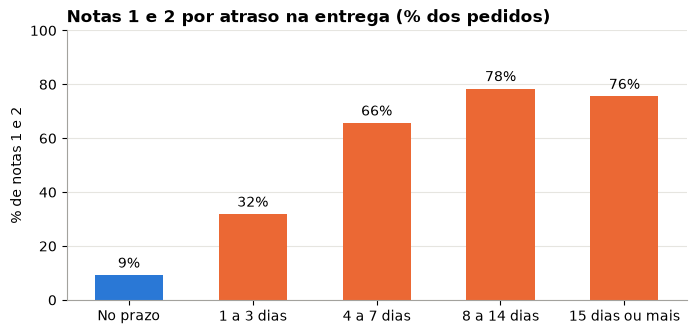

In [11]:
faixas = [-1000, 0, 3, 7, 14, 1000]
nomes = ['No prazo', '1 a 3 dias', '4 a 7 dias', '8 a 14 dias', '15 dias ou mais']
entregues['faixa_atraso'] = pd.cut(entregues['dias_atraso'], bins=faixas, labels=nomes)

por_faixa = entregues.groupby('faixa_atraso', observed=True).agg(pedidos=('order_id', 'size'),
                                                                 pct_nota_1_2=('nota_ruim', 'mean'))
print(por_faixa.round(2))
pct = por_faixa['pct_nota_1_2'] * 100

cores = [AZUL] + [LARANJA] * 4
plt.figure(figsize=(8, 3.5))
barras = plt.bar(nomes, pct, color=cores, width=0.55)
plt.bar_label(barras, labels=[f'{v:.0f}%' for v in pct], padding=3)
plt.ylim(0, 100)
plt.title('Notas 1 e 2 por atraso na entrega (% dos pedidos)')
plt.ylabel('% de notas 1 e 2')
plt.show()

- As notas 1 e 2 sobem de 9% (no prazo) para **32%** com 1 a 3 dias de atraso e **66%** com 4 a 7 dias.
- Acima de uma semana, ficam em torno de 77%: três em cada quatro clientes dão nota 1 ou 2, e a proporção para de subir porque quase todos já estão insatisfeitos.

A hipótese se sustenta: a insatisfação cresce com o atraso, e o estrago acontece já na primeira semana.

## 4.7 Quando o cliente atrasado avalia?

A data de criação da pesquisa (`review_creation_date`) indica quando a Olist pediu a avaliação. **Hipótese:** a pesquisa sai depois da entrega; se for assim, todo cliente avalia já com o produto em mãos. Para testar, comparo a criação da pesquisa com o dia da entrega (no prazo) e com o dia prometido (atrasados).

In [12]:
no_prazo = entregues[~entregues['atrasado']]
atrasados = entregues[entregues['atrasado']]

print('No prazo: dias entre a entrega e a pesquisa (mediana):',
      (no_prazo['review_creation_date'] - no_prazo['dia_entrega']).dt.days.median())
print('Atrasados: dias entre a data prometida e a pesquisa (mediana):',
      (atrasados['review_creation_date'] - atrasados['order_estimated_delivery_date']).dt.days.median())

antes = atrasados['review_creation_date'] < atrasados['dia_entrega']
print()
print(f'Atrasados com pesquisa criada antes da entrega: {antes.mean() * 100:.0f}%')
print(f'Notas 1 e 2, pesquisa antes da entrega: {atrasados.loc[antes, "nota_ruim"].mean() * 100:.0f}%')
print(f'Notas 1 e 2, pesquisa depois da entrega: {atrasados.loc[~antes, "nota_ruim"].mean() * 100:.0f}%')

No prazo: dias entre a entrega e a pesquisa (mediana): 1.0
Atrasados: dias entre a data prometida e a pesquisa (mediana): 2.0

Atrasados com pesquisa criada antes da entrega: 73%
Notas 1 e 2, pesquisa antes da entrega: 75%
Notas 1 e 2, pesquisa depois da entrega: 23%


A hipótese não se sustenta para os atrasados:

- No prazo, a pesquisa sai **1 dia depois da entrega**.
- Nos atrasados, a pesquisa sai **2 dias depois da data prometida**, chegue o produto ou não. Em **73%** dos atrasados, o cliente foi convidado a avaliar antes de receber.
- Entre quem avaliou antes de receber, 75% deram nota 1 ou 2; entre quem avaliou depois, 23%.

A regra encontrada nos dados aparece também na [descrição oficial da base no Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): o cliente recebe a pesquisa por e-mail quando recebe o produto ou quando vence a data prometida.

Leitura: a maior parte dos atrasados avalia a espera, e não o produto. A nota baixa desses pedidos é uma consequência direta do atraso.

## 4.8 Quanto das notas ruins o atraso explica?

O atraso derruba a nota, mas atinge só 6,8% dos pedidos. Para saber o peso dele no total, conto de onde vêm as notas 1 e 2.

In [13]:
ruins = entregues[entregues['nota_ruim']]
print(f'Notas 1 e 2 em pedidos entregues: {len(ruins):,}')
print(ruins['atrasado'].value_counts())
print(f'Parcela vinda de atrasos: {ruins["atrasado"].mean() * 100:.0f}%')

Notas 1 e 2 em pedidos entregues: 12,228
atrasado
False    8247
True     3981
Name: count, dtype: int64
Parcela vinda de atrasos: 33%


Das **12.228** notas 1 e 2 em pedidos entregues, **3.981 (33%)** vêm de pedidos atrasados. Os outros dois terços vêm de pedidos entregues no prazo, por causas que os atrasos não explicam.

Leitura: o atraso derruba a nota e é a causa isolada mais clara de insatisfação, mas eliminar todos os atrasos resolveria cerca de um terço das notas ruins.

## 4.9 O que os clientes escrevem

As comparações até aqui usam a nota. O comentário explica o **porquê** da nota. Antes de ler o texto, conto com Python quem escreve, por nota.

In [14]:
tem_comentario = nota_pedido['review_comment_message'].notna()
(tem_comentario.groupby(nota_pedido['review_score']).mean() * 100).round(0)

review_score
1    77.0
2    68.0
3    44.0
4    31.0
5    36.0
Name: review_comment_message, dtype: float64

**77%** de quem dá nota 1 escreve um comentário, contra **36%** de quem dá nota 5. O cliente insatisfeito escreve mais, então os comentários dão mais detalhe sobre os problemas do que sobre os elogios.

São mais de 40 mil comentários: ler à mão é inviável, e contar palavras só responde perguntas que eu já sei fazer. Para encontrar os temas, usei IA:

- Modelo: Gemini 4 Argon, esforço alto, pela ferramenta de linha de comando agy.
- Uma chamada por nota: os comentários de nota 1 foram analisados só com os de nota 1, os de nota 5 só com os de nota 5, e assim por diante, para que elogios e reclamações não se misturem.
- Primeira tentativa, descartada: enviei todos os comentários de cada nota. As cinco chamadas chegaram ao modelo com o mesmo tamanho (cerca de 55 mil tokens), tanto a nota 2 (2 mil comentários) quanto a nota 5 (20 mil). A ferramenta corta textos acima de cerca de 200 mil caracteres sem avisar, então o modelo leu só uma parte.
- Versão usada: uma **amostra aleatória de 1.500 comentários por nota** (semente 42), que cabe no limite. O script confere o tamanho recebido antes de aceitar o resultado.
- Os comentários foram tratados como dados, com instrução para o modelo ignorar qualquer pedido escrito neles.
- As parcelas são estimativas do modelo, não contagens. Servem para apontar os temas, não para medir com precisão.

O script está em scripts/temas_comentarios.py, e o resultado completo de cada nota (temas, exemplos literais e observações) está em docs/temas_comentarios/. Os três temas mais citados em cada nota:

| Nota | Temas mais citados (estimativa do modelo) |
|---|---|
| 1 | atraso ou não entrega (cerca de 50%); atendimento, troca e reembolso (cerca de 22%); entrega incompleta (cerca de 15%) |
| 2 | atraso ou não recebimento (cerca de 35%); entrega incompleta (cerca de 18%); produto errado ou diferente do anúncio (cerca de 16%) |
| 3 | atraso ou prazo longo (cerca de 28%); qualidade inferior (cerca de 20%); produto diferente do anúncio (cerca de 18%) |
| 4 | entrega rápida ou no prazo (40% a 45%); satisfação sem ressalvas (35% a 40%); ressalvas de qualidade ou tamanho (12% a 15%) |
| 5 | entrega antes do prazo (55% a 60%); qualidade do produto (35% a 40%); elogios curtos (25% a 30%) |

Leitura:

- A entrega domina as duas pontas. Atraso é o tema número 1 das notas 1, 2 e 3; chegar antes do prazo é o tema número 1 das notas 4 e 5. Compatível com o item 4.6: a nota mede principalmente a entrega.
- A entrega incompleta aparece como tema próprio nas notas 1 e 2 (cerca de 15% a 18%): o cliente comprou mais de uma unidade ou vários itens e recebeu só parte.
- Os comentários trazem um problema que os números não mostram: o cliente **paga frete para receber em casa e precisa buscar nos Correios**. Aparece entre os temas das notas 1 a 4.
- Os nomes de lojas nos comentários (*lannister*, *stark*, *baratheon*) são substituições feitas na anonimização da base, segundo a [descrição oficial no Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

## 5.1 Clientes: quem é a mesma pessoa?

Na validação de orders, o `customer_id` não se repetia em nenhum pedido, o que levantou a hipótese de que ele não identifica a pessoa. A tabela de clientes tem também o customer_unique_id. Se a hipótese estiver certa, o customer_id é único por linha e o customer_unique_id se repete para quem comprou mais de uma vez.

In [15]:
print('Linhas:', len(customers))
print('customer_id distintos:', customers['customer_id'].nunique())
print('customer_unique_id distintos:', customers['customer_unique_id'].nunique())
print()
print('Vazios:', customers.isnull().sum().sum(), '| linhas idênticas:', customers.duplicated().sum())
print('Clientes sem pedido:', (~customers['customer_id'].isin(orders['customer_id'])).sum())
print('Pedidos sem cliente:', (~orders['customer_id'].isin(customers['customer_id'])).sum())

Linhas: 99441
customer_id distintos: 99441
customer_unique_id distintos: 96096



Vazios: 0 | linhas idênticas: 0


Clientes sem pedido: 0
Pedidos sem cliente: 0


- 99.441 customer_id, um para cada pedido, e **96.096 customer_unique_id**.
- A hipótese se confirma: o customer_id é um código do pedido, e a pessoa é o customer_unique_id.
- Sem vazios, duplicatas ou órfãos.

**Decisão:** toda análise de cliente e recompra usa o customer_unique_id.

## 5.2 Taxa de recompra

Uso os mesmos pedidos que formam o valor vendido (recorte, sem cancelados e indisponíveis) e conto quantos pedidos cada pessoa fez.

In [16]:
pedidos = orders.merge(customers, on='customer_id')
vendas = pedidos[pedidos['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')
                 & ~pedidos['order_status'].isin(['canceled', 'unavailable'])].copy()

pedidos_por_cliente = vendas.groupby('customer_unique_id').size()
print(f'Clientes: {len(pedidos_por_cliente):,}')
print(f'Com mais de um pedido: {(pedidos_por_cliente > 1).sum():,} ({(pedidos_por_cliente > 1).mean() * 100:.1f}%)')

Clientes: 94,707
Com mais de um pedido: 2,875 (3.0%)


**2.875 de 94.707 clientes (3,0%)** fizeram mais de um pedido.

No item 4.2, uma compra podia virar vários pedidos no mesmo minuto. Se isso for comum, parte desses 3% não é recompra, e sim uma compra dividida. Para testar, conto em quantos dias diferentes cada cliente comprou.

In [17]:
vendas['dia_compra'] = vendas['order_purchase_timestamp'].dt.date
dias_por_cliente = vendas.groupby('customer_unique_id')['dia_compra'].nunique()
print(f'Clientes que compraram em mais de um dia: {(dias_por_cliente > 1).sum():,} ({(dias_por_cliente > 1).mean() * 100:.1f}%)')

Clientes que compraram em mais de um dia: 2,054 (2.2%)


Só **2.054 clientes (2,2%)** compraram em mais de um dia. Os outros 821 que "repetiram" fizeram vários pedidos no mesmo dia, o que é compatível com uma compra dividida.

**Decisão:** recompra é voltar a comprar em outro dia. A taxa de recompra é de 2,2%: de cada 100 clientes, 98 compram uma vez só no período.

## 5.3 A nota baixa reduz a recompra?

Pego o **primeiro pedido** de cada cliente (ordeno por data e uso `drop_duplicates`, que mantém a primeira linha), junto a nota desse pedido e marco se o cliente voltou em outro dia.

Antes de comparar notas, um cuidado: quem comprou pela primeira vez em ago/2018 teve poucos dias para voltar até o fim da base. **Hipótese:** a recompra cai para os clientes mais recentes só por falta de tempo. Testo com a recompra por trimestre da primeira compra.

In [18]:
primeiro = (vendas.sort_values('order_purchase_timestamp')
                  .drop_duplicates(subset='customer_unique_id', keep='first')
                  .merge(nota_pedido[['order_id', 'review_score']], on='order_id', how='left'))
primeiro['voltou'] = primeiro['customer_unique_id'].map(dias_por_cliente) > 1

trimestre = primeiro['order_purchase_timestamp'].dt.to_period('Q')
(primeiro.groupby(trimestre)['voltou'].mean() * 100).round(1)

order_purchase_timestamp
2017Q1    3.7
2017Q2    3.9
2017Q3    3.5
2017Q4    2.3
2018Q1    1.9
2018Q2    1.3
2018Q3    0.6
Freq: Q-DEC, Name: voltou, dtype: float64

A recompra fica entre 3,5% e 3,9% para quem chegou até o 3º tri/2017 e cai trimestre a trimestre até 0,6% no 3º tri/2018. A hipótese se sustenta: clientes recentes ainda não tiveram tempo de voltar, e misturá-los puxaria a comparação.

**Decisão:** comparo só clientes cuja primeira compra foi **até fev/2018**, que tiveram pelo menos 6 meses para voltar. Agrupo as notas em três grupos com pd.cut(): insatisfeito (1 e 2), neutro (3) e satisfeito (4 e 5).

            clientes  recompra_%
grupo_nota                      
Nota 1 e 2      8008         2.2
Nota 3          4865         2.5
Nota 4 e 5     43010         3.0


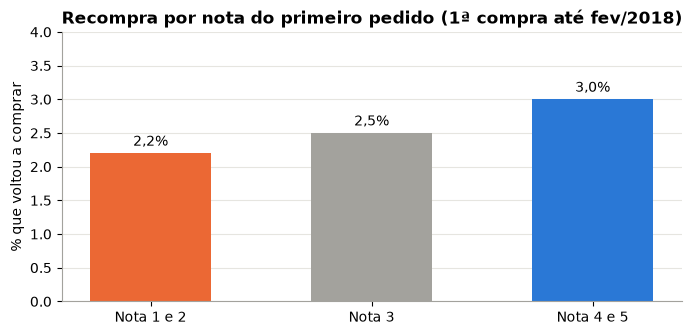

In [19]:
com_tempo = primeiro[primeiro['order_purchase_timestamp'] < '2018-03-01'].copy()
com_tempo['grupo_nota'] = pd.cut(com_tempo['review_score'], bins=[0, 2, 3, 5],
                                 labels=['Nota 1 e 2', 'Nota 3', 'Nota 4 e 5'])

recompra = com_tempo.groupby('grupo_nota', observed=True)['voltou'].agg(['size', 'mean'])
recompra['mean'] = (recompra['mean'] * 100).round(1)
print(recompra.rename(columns={'size': 'clientes', 'mean': 'recompra_%'}))

plt.figure(figsize=(8, 3.5))
barras = plt.bar(recompra.index.astype(str), recompra['mean'], color=[LARANJA, CINZA, AZUL], width=0.55)
plt.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in recompra['mean']], padding=3)
plt.ylim(0, 4)
plt.title('Recompra por nota do primeiro pedido (1ª compra até fev/2018)')
plt.ylabel('% que voltou a comprar')
plt.show()

- Clientes satisfeitos (nota 4 e 5) voltam em **3,0%** dos casos; insatisfeitos (1 e 2), em **2,2%**: cerca de um quarto a menos.
- Os grupos são grandes (8 mil insatisfeitos, 43 mil satisfeitos), o que reduz a chance de a diferença ser acaso de poucos casos.
- Mas mesmo os satisfeitos quase não voltam: 97 em cada 100 compram uma vez só.

Confiro o mesmo efeito direto pelo atraso no primeiro pedido.

In [20]:
entrega_primeiro = com_tempo.merge(entregues[['order_id', 'atrasado']], on='order_id')
(entrega_primeiro.groupby('atrasado')['voltou'].mean() * 100).round(1)

atrasado
False    2.9
True     2.0
Name: voltou, dtype: float64

Quem teve o primeiro pedido atrasado volta em **2,0%** dos casos, contra **2,9%** de quem recebeu no prazo, na mesma direção da nota.

Leitura: a nota baixa reduz a recompra, mas não explica o problema principal. A recompra é baixa para todos, inclusive para quem saiu satisfeito.

## Resumo de avaliações e clientes

| # | Verificação | O que os dados mostraram | Decisão |
|---|---|---|---|
| 4.2 | Avaliação compartilhada | 789 avaliações em mais de um pedido, 100% do mesmo cliente, 63% com vendedores diferentes | nota vale para cada pedido da compra |
| 4.2 | Pedido com várias avaliações | 547 pedidos, 202 com notas diferentes | última avaliação respondida |
| 4.3 | Vazios | só em título e comentário (opcionais, segundo a descrição da base); 768 pedidos sem avaliação | comparações pela nota |
| 4.4 | Distribuição | 77% de notas 4 e 5; 11,5% de nota 1 | comparar pela % de notas 1 e 2, não pela média |
| 4.5 | Atraso e prazo | 6,8% atrasados; prazo mediano 10,2 dias, CV de 76% | atraso comparado por dia |
| 4.6 | Nota x atraso | 9% de notas 1 e 2 no prazo, 61% nos atrasados; sobe já na 1ª semana | o atraso derruba a nota |
| 4.7 | Momento da avaliação | 73% dos atrasados avaliam antes de receber (regra confirmada na descrição da base) | nota do atrasado mede a espera |
| 4.8 | Peso do atraso | 33% das notas 1 e 2 | dois terços das notas ruins têm outra causa |
| 4.9 | Comentários (IA, amostra de 1.500 por nota) | atraso lidera as notas 1 a 3; entrega antes do prazo lidera as notas 4 e 5; entrega incompleta e retirada nos Correios aparecem como temas | temas como indicação, não como medida |
| 5.1 | Identidade do cliente | customer_id é do pedido; 96.096 pessoas | cliente = customer_unique_id |
| 5.2 | Recompra | 3,0% com mais de um pedido, 2,2% em outro dia | recompra = comprar em outro dia |
| 5.3 | Nota x recompra | 3,0% (satisfeitos) contra 2,2% (insatisfeitos) | comparar só quem teve 6 meses para voltar |

**Resposta à pergunta:** sim nas duas partes, com pesos diferentes. O atraso derruba a nota com força: as notas 1 e 2 sobem de 9% para 61%, e a maioria dos atrasados avalia antes mesmo de receber. A nota baixa reduz a recompra, mas pouco, porque a recompra é baixa para todos: 97% dos clientes satisfeitos também não voltam.